# CCE2502 Assignment II - Logistic Regression
### Year 2024-2025- Semester II



A number of functions are given, including the partially completed gradient descent optimizer.

Please follow instructions in the assignment specifications document.


In [1]:
# import useful packages
import numpy as np
import matplotlib.pyplot as plt
import csv

%matplotlib inline

In [2]:
# Do not carry out any changes to the code in this cell

def lr_loss_function(y_target,y_predicted):
    """
    y_target: actual gold labels (vector of size(m,))
    y_predicted : predicted probabilities for positive class (vector of size (m,))
    returns categorical cross entropy loss
    """
    m=y_target.shape[0]
    L = -(y_target*np.log(y_predicted) + (1-y_target)*np.log(1-y_predicted)).sum()/m
    return L


def predict_y_prob(W,D):
    """
    W is the weight vector [[w_0],[w_1],[w_2],...] of size [N+1,1]
    where N is number of features, excluding bias
    D is the feature matrix [m,N] where m is the number of examples
    return a vector of size (m,1)
    """
    m = D.shape[0]
    bias = np.ones([m,1], dtype=float)
    X = np.concatenate((bias,D),axis=1)
    z = np.matmul(W.T,X.T)
    y = 1/(1+np.exp(-z))
    #
    return y.T

def get_accuracy(W,X,y):
    """
    W is the weight vector [[w_0],[w_1],[w_2],...] of size [N+1,1]
    where N is number of features, excluding bias
    X is the feature matrix [m,N] where m is the number of examples
    y is the gold label vector of size (m,)
    Computes and returns the accuracy in predicting the positive class and returns a scalar
    """
    Y_pred = (predict_y_prob(W,X)>=0.5).astype(int)
    #
    return (Y_pred.ravel()==y).astype(int).sum()/y.shape[0]

def display_results(model):
    #
    history_train_loss = model['history']['train_loss']
    history_val_loss = model['history']['val_loss']
    t=range(len(history_train_loss))
    p1, p2 = plt.plot(t,history_train_loss,'b',t,history_val_loss,'r')
    plt.legend([p1,p2], ['Train loss','Val loss'])
    #
    print('train acc : ', model['train_acc'])
    print('val acc   : ', model['val_acc'])
    #
    print('Weights : ', model['weights'].ravel())
    
    ###
    plt.show()
    ###
    
    return 0

# Use this function for plotting datasets as scatter graphs
def data_scatter_plot(X,y):
    """
    Plots a scatter graph for a 2-D dataset
    X : Feature numpy array of size (m,N), 
            m=number of examples (rows)
            N = number of features (columns)
            If N>2, first two features taken in consideration
    y : Output label numpy array of size (m,1) or (m,)
    """
    mk ={0:'or', 1:'ob'}
    plt.plot(X[:,0][y[:]==0] , X[:,1][y[:]==0], mk[0])
    plt.plot(X[:,0][y[:]==1] , X[:,1][y[:]==1], mk[1])

In [3]:
# Gradient Descent algorithm that learns the model parameters
# The update equations require the partial derivatives of the loss function
# with respect to the weights or parameter of the model
#
def lr_train_model(X_data, 
                   y_data, 
                   reshuffle = 'yes',
                   split_frac=0.8, 
                   init_weights=0.00001, 
                   no_iterations=2000,
                   alpha = 0.001,
                   phi = 0.001):
    """
    X_data : data feature matrix (including bias x_0 = 1.0)
    y_data : data output values
    split_frac : data split fraction, we require the split to compute validation mse
        if split_frac = -1 (or negative), then dataset is not split and train and val portions are the same
    init_weights : initial weights (all same value)
        if init_weights = -1 (or negative), then random weights are chosen
    alpha : learning rate
    phi : regularisation constant
    W : weights vector
    """
    #
    idx = np.arange(0, y_data.shape[0])
    if reshuffle == 'yes':
        np.random.shuffle(idx)
    X_data = np.copy(X_data[idx])
    y_data = np.copy(y_data[idx])
    #
    if split_frac < 0.0:
        y_train, y_val, X_train, X_val = y_data, y_data, X_data, X_data
    else:
        split = int(y_data.shape[0]*split_frac)
        y_train, y_val, X_train, X_val  = y_data[0:split], y_data[split:], X_data[0:split], X_data[split:]
    #
    N = X_data.shape[1] # number of features
    print("Number of input features :",N)
    if init_weights < 0.0:
        W = 0.5*(np.random.rand((N+1))-0.5).reshape(N+1,1)
    else:
        W = np.full((N+1,1), init_weights) # initialise weight vectors to the same value
    print("Initial Weights:",W)
    m=y_train.shape[0]
    history_loss=[]
    history_val_loss=[]
    
    #
    for itr in range(no_iterations):
        y_pred_pr = predict_y_prob(W,X_train).ravel()
        loss = lr_loss_function(y_train,y_pred_pr)
        history_loss.append(loss)
        history_val_loss.append(lr_loss_function(y_val,predict_y_prob(W,X_val).ravel()))
        #
        #
        #######################################################################
        #
        # Add update equations in this section 
        # W[0] is the bias term (no regularisation)
        #
        err = (y_pred_pr - y_train.ravel()).reshape((-1,1)) #(y - t), reshaping for dot product below
        
        bias = np.ones(X_train.shape[0])
        X_temp = np.column_stack([bias,X_train])
        
        grad = (1.0/(2*m)) * X_temp.T.dot(err) #1/2m * X^T (y - t)
        
        grad[1:] += 2 * phi * W[1:] # + 2phi*w except for W[0]
        
        W -= alpha * grad # final update
        #######################################################################
    #
    #
    return {'weights':W, 
            'history':{'train_loss':history_loss,
                                    'val_loss':history_val_loss},
            'train_acc':get_accuracy(W,X_train,y_train),
            'val_acc':get_accuracy(W,X_val,y_val)}

## TASK 1
This task is on adding the gradient descent update equations to the lr_train_model() function 
provided in the attached jupyter notebook and gaining experience in using the lr_train_model(), 
the associated functions and the helper functions, namely data_scatter_plot() and 
display_results(). \
\
Note that the lr_train_model() function automatically splits the dataset into train and validation 
and the display_results() plots loss against epochs and computes accuracy. Take some time to 
understand the lr_train_model() function. 

a) Use the csv python module to load the data in the binary_classification_basic.csv file. 
The first two columns are the input features (X1, X2) and the third column is the output 
variable (y). 

In [4]:
f = open('binary_classification_basic.csv',mode='r')
reader = csv.DictReader(f)
dict_list = []
num_rows = 0

for row in reader :
    num_rows += 1
    dict_list.append(row)

X = np.zeros(shape=(num_rows,2),dtype=float)
y = np.zeros(shape=(num_rows))

for i in range(num_rows) :
    X[i] = (dict_list[i]['X1'],dict_list[i]['X2'])
    y[i] = dict_list[i]['y']



b) Using the function provided, plot the scatter graph.

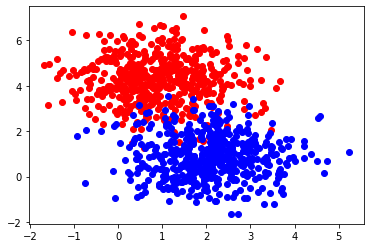

In [5]:
data_scatter_plot(X,y)

c) The regularized categorical cross entropy loss function is given below. Derive the 
partial derivatives of the loss function with-respect-to the model parameters, w.
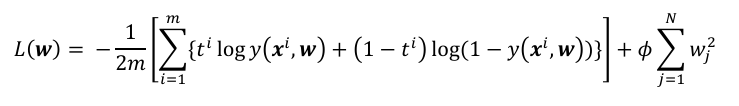\
where $m$ is the number of examples in the dataset, $i$ is an index to the $i$ th example, $t$ is the target variable, $\textbf{\textit{x}}$ is the input vector and $\textbf{\textit{w}}$ is the weight vector. \
\
$\nabla_{w} L(\underline{w})=-\frac{1}{2m}\sum_{i=1}^{m}[(\frac{t^{i}}{y(\underline{x}^{i},\underline{w})}+\frac{t^{i}-1}{1-y(\underline{x}^{i},\underline{w})})\nabla_{w}y(\underline{x}^{i},\underline{w})]+2\phi w$ \
\
Then simplified to 
$\nabla_{w} L(\underline{w})=\frac{1}{2m}X^T(y-t)+2\phi w$  (all shown in attached working)\
\
d) Complete the lr_train_model() function by adding the gradient descent update rules in 
the space indicated. Note that the bias term should not be regularized. (completed above)\
\
e) Using the lr_train_model() function train a model on the binary_classification_basic 
dataset. Remember to make use of the display_results() function to get insight and 
debug the model. 

Number of input features : 2
Initial Weights: [[1.e-05]
 [1.e-05]
 [1.e-05]]
train acc :  0.88875
val acc   :  0.905
Weights :  [ 0.08232117  0.30593527 -0.39302447]


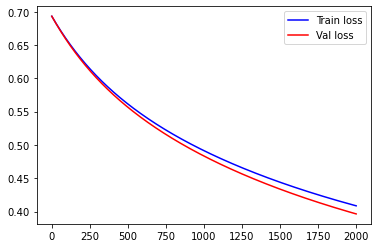

0

In [6]:
# models = []

# for i in range(5) :
#     testalpha = 0.1**(i+1)
#     model = lr_train_model(X,y,alpha=testalpha)
#     models.append(model)
#     display_results(model)
    
model = lr_train_model(X,y)
display_results(model)



f) Superimpose the decision boundary learnt by the model onto the dataset scatter plot. 
The decision boundary lies on the line where the output of the sigmoid function is 0.5, ie. $\frac{1}{1+e^{-(w_0+w_1x_1+w_2x_2)}}=0.5$, which simplifies to $x_2 = - \frac{w_0+w_1x_1+ln(1)}{w_2}$, but $ln(1) = 0$, so the decision_boundary function is defined as below. 

0.02770609555774602 0.9356351643369788


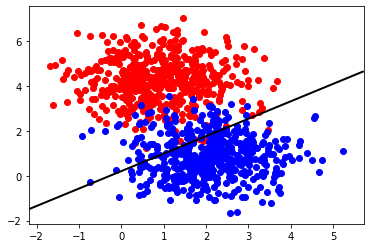

In [7]:
def norm(X) : 
    ranges = np.zeros(2)
    mins = np.zeros_like(ranges)

    for i in range(2) :
        max, mins[i] = np.max(X[:,i]), np.min(X[:,i])
        ranges[i] = max - mins[i]

    normX = np.column_stack([(X[:,0] - mins[0]) / ranges[0], (X[:,1] - mins[1]) / ranges[1]]) 
    return normX

def plot_decision_boundary(model, num_weights=3, normalised=False) :
    ws = np.zeros(num_weights)
    ws = model['weights'].ravel()
    
    if normalised == True :
        x1g = np.linspace(-0.2, 1.2, 200)
        x2g = np.linspace(-0.2, 1.2, 200)
        data_scatter_plot(norm(X),y)
    else : 
        x1g = np.linspace(X[:,0].min() - 0.5, X[:,0].max() + 0.5, 200)
        x2g = np.linspace(X[:,1].min() - 0.5, X[:,1].max() + 0.5, 200)
        data_scatter_plot(X,y)
        
    xx, yy = np.meshgrid(x1g, x2g)
    
    zz = ws[0] + ws[1]*xx + ws[2]*yy
    
    if num_weights > 3:
        zz += ws[3]*(xx**2) + ws[4]*(yy**2) + ws[5]*(xx*yy)
    
    pp = 1/(1+np.exp(-zz))
        
    plt.contour(xx, yy, pp, levels=[0.5], colors='black', linewidths=2)
    print(pp.min(), pp.max())
    
    
plot_decision_boundary(model)

## TASK 2
This task is on adapting the logistic regression model to a non-linearly separable dataset. 

a) Use the csv python module to load the data in the binary_classification_advanced.csv file. The first two columns are the input features (X1, X2) and the third column is the output variable (y).

In [8]:
f = open('binary_classification_advanced.csv',mode='r')
reader = csv.DictReader(f)
dict_list = []
num_rows = 0

for row in reader :
    num_rows += 1
    dict_list.append(row)

X = np.zeros(shape=(num_rows,2),dtype=float)
y = np.zeros(shape=(num_rows))

for i in range(num_rows) :
    X[i] = (dict_list[i]['X1'],dict_list[i]['X2'])
    y[i] = dict_list[i]['y']



b) Using the function provided plot the scatter graph.

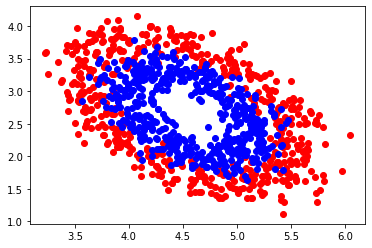

In [9]:
data_scatter_plot(X,y)

c) Using the lr_train_model() function, train a model on the binary_classification_advanced dataset and explain any poor result. (Note: to get some 
insight you can also superimpose the decision boundary learnt by the model onto the dataset scatter plot).

Number of input features : 2
Initial Weights: [[1.e-05]
 [1.e-05]
 [1.e-05]]
train acc :  0.51125
val acc   :  0.445
Weights :  [-0.00085413  0.0060594  -0.01084114]


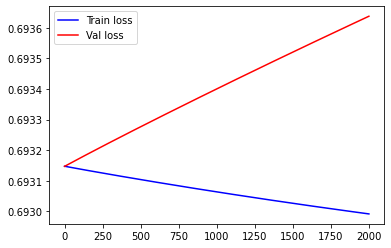

0.4913158341449009 0.5080333051767594


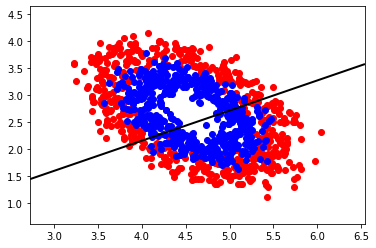

In [34]:
model = lr_train_model(X,y)
display_results(model)
plot_decision_boundary(model,3)

This dataset is not separable, so the weights obtained are continuously skewed in a wrong direction leading to a decision boundary that does not even intersect the dataset, which is obviously an incredibly poor result.

d) Manually, find higher order terms of the input features (X1, X2) that improve the classification accuracy. Explain your answer and your reasoning. (Note: consider using scatter plots in your explanation)

Number of input features : 5
Initial Weights: [[1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]]
train acc :  0.585
val acc   :  0.56
Weights :  [ 0.00066649  0.00882433  0.00358592 -0.01709634 -0.07891618  0.07179281]


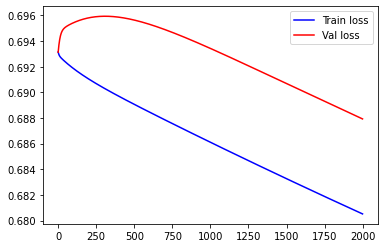

0.2928463588741182 0.5090550186692746


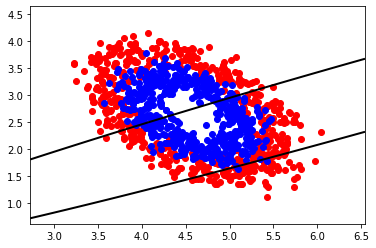

In [11]:
# initial attempt with X1^2, X2^2, and X1*X2 since the ideal decision boundary is in the shape of an ellipse

newX = np.hstack([X,X**2,(X[:,0]*X[:,1]).reshape(X.shape[0],-1)]) #x1, x2, x1^2, x2^2, x1*x2
model = lr_train_model(newX,y)
display_results(model)
plot_decision_boundary(model,6)


Number of input features : 5
Initial Weights: [[1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]]
train acc :  0.74
val acc   :  0.72
Weights :  [-0.77013658  3.05463384  3.58002425 -6.24423555 -6.25036619  5.05009192]


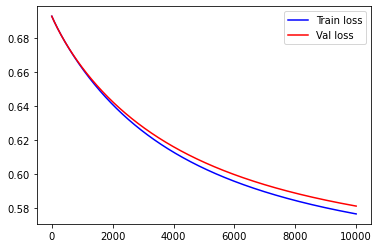

0.00025491722362434133 0.6708235206566626


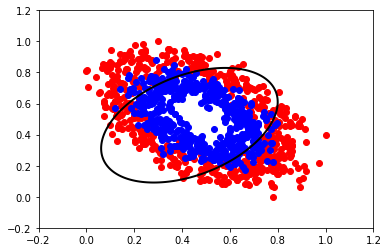

In [12]:
# training the model on the normalised dataset with adjusted phi and alpha
newX = np.hstack([norm(X), norm(X)**2, (norm(X)[:,0]*norm(X)[:,1]).reshape(norm(X).shape[0],-1)]) #x1, x2, x1^2, x2^2, x1*x2

model = lr_train_model(newX,y,alpha=0.35, phi=0.0001, no_iterations=10000)
display_results(model)
plot_decision_boundary(model,6,normalised=True)

Number of input features : 5
Initial Weights: [[1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]
 [1.e-05]]
train acc :  0.85625
val acc   :  0.86
Weights :  [-12.43447863  30.12182756  29.66799886 -27.81129519 -25.68765108
  -7.54146348]


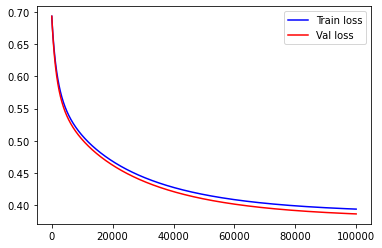

3.852526806266363e-13 0.902096208155866


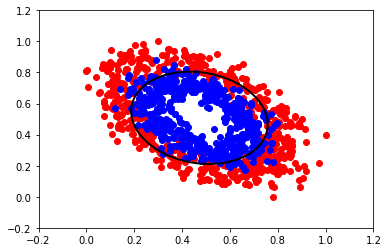

In [13]:
# increasing no_iterations and varying phi and alpha accordingly gives a high accuracy model

model = lr_train_model(newX,y,alpha=0.9, phi=0.00001, no_iterations=100000)
display_results(model)
plot_decision_boundary(model,6,normalised=True)

## TASK 3

https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html
    

a) In no more than 100 words, explain how a neural network can learn non-linear separable 
dataset and obtains an acceptable prediction accuracy.

A neural network can only learn non-linear separable datasets if a non-linear activation function is used in at least one of its hidden layers. This is necessary because these activation functions warp the input space in some way, allowing the model to learn decision boundaries that are non-linear, through training with backpropagation. The accuracy of the model can also be helped by increasing the number of hidden layers, since this can warp the input space in multiple ways, leading to a more intricate and accurate decision boundary.

b) Use the sklearn.neural_network.MLPClassifier() module (see jupyter notebook for link 
to API) to learn a non-linear model for the binary_classification_advanced dataset. 
(Note: you are expected to find an efficient structure that models the dataset) 

In [14]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

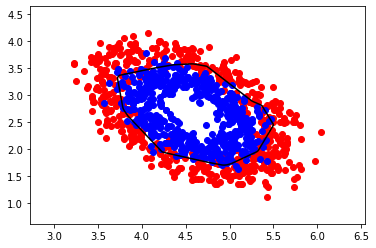

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
clf = MLPClassifier(max_iter=1000, hidden_layer_sizes=(20,20))
clf.fit(X_train, y_train)
Z = clf.predict(X_test)

x1g = np.linspace(X[:,0].min() - 0.5, X[:,0].max() + 0.5, 200)
x2g = np.linspace(X[:,1].min() - 0.5, X[:,1].max() + 0.5, 200)
data_scatter_plot(X,y)
    
xx, yy = np.meshgrid(x1g, x2g)

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = clf.predict_proba(grid_points)[:,1]
Z = Z.reshape(xx.shape)


plt.contour(xx, yy, Z, levels = [0.5], colors='black')



c) Explain how you would check whether the neural network is performing as it should, 
without computing the accuracy or any other quantitative evaluation metric.

The results of the neural network above were observed by overlaying the decision boundary obtained by predicting all the points of the meshgrid the data scatter plot of the dataset is plotted on. Through testing, 2 hidden layers of 20 neurons each, with a maximum of 1000 epochs was found to be a suitable data structure for this classification, as can be seen on the plot above.

# References
- Documentation: 
    * Numpy: [numpy.org](https://numpy.org/)
    * Scikit-Learn: [scikit-learn.org/stable/index.html](https://scikit-learn.org/stable/index.html)
    * Matplotlib: [matplotlib.org/stable/](https://matplotlib.org/stable/)
- Blogs:
    * [Understanding how to use the CSV module](https://www.geeksforgeeks.org/working-csv-files-python/)
    * [Finding the partial derivatives in Task 1c](https://math.stackexchange.com/questions/78575/derivative-of-sigmoid-function-sigma-x-frac11e-x)
- Generative AI: [chatgpt.com](https://chatgpt.com)
    * AI was used here to debug some parts of code related to plotting.